<a href="https://colab.research.google.com/github/munabila/My-Project/blob/main/prediksi_kegagalan_mesin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Membaca dataset dari file CSV yang tersedia
df = pd.read_csv('/content/ai4i2020.csv')

# Menampilkan informasi awal dataset
print("Dataset berhasil dimuat!")
display(df.tail(-1))

Dataset berhasil dimuat!


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
10,11,H29424,H,298.4,308.9,1782,23.9,24,0,0,0,0,0,0
11,12,H29425,H,298.6,309.1,1423,44.3,29,0,0,0,0,0,0
12,13,M14872,M,298.6,309.1,1339,51.1,34,0,0,0,0,0,0
13,14,M14873,M,298.6,309.2,1742,30.0,37,0,0,0,0,0,0
14,15,L47194,L,298.6,309.2,2035,19.6,40,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


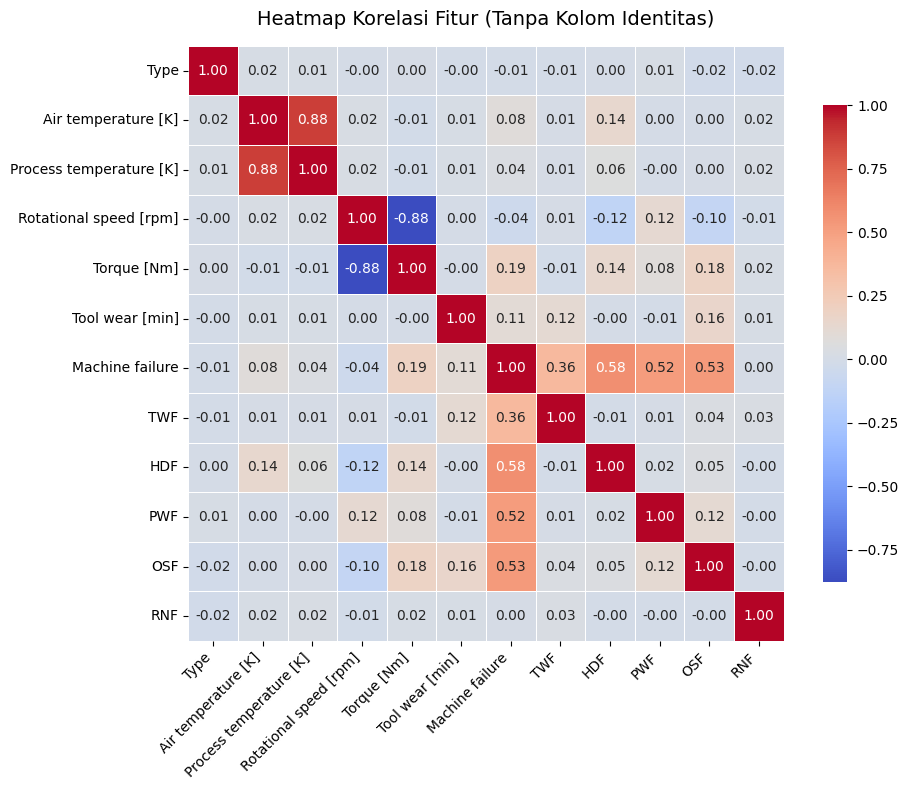

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Menghapus kolom identitas yang tidak diperlukan
cols_to_exclude = ['UDI', 'Product ID']
df_corr_data = df.drop(columns=[col for col in cols_to_exclude if col in df.columns])

# 2. Mengonversi fitur kategorikal ke representasi numerik jika perlu
df_corr_numeric = df_corr_data.copy()
if 'Type' in df_corr_numeric.columns:
    df_corr_numeric['Type'] = df_corr_numeric['Type'].astype('category').cat.codes

# 3. Menghitung matriks korelasi
correlation_matrix = df_corr_numeric.corr()

# 4. Membuat Visualisasi Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": .8}
)

plt.title("Heatmap Korelasi Fitur (Tanpa Kolom Identitas)", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Mengaktifkan tabel data interaktif Colab dan menampilkan DataFrame df
from google.colab import data_table
data_table.enable_dataframe_formatter()
display(df)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [ ]:
# Memeriksa jumlah nilai yang hilang (missing value) pada setiap kolom
missing_values_summary = df.isnull().sum()
display(missing_values_summary.to_frame(name='Jumlah Missing Value'))

,Jumlah Missing Value
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
# Memeriksa jumlah baris data yang duplikat
sum_duplicates = df.duplicated().sum()
print(f"Jumlah data duplikat: {sum_duplicates}")

Jumlah data duplikat: 0


In [ ]:
# Memisahkan fitur (X) dan target (y)
y = df['Machine failure']
X = df.drop(columns=['Machine failure'])

# Menampilkan informasi ukuran data X dan y
print(f"Ukuran X (fitur): {X.shape}")
print(f"Ukuran y (target): {y.shape}")

# Menampilkan beberapa data teratas
print("\n--- 5 Data Teratas Fitur (X) ---")
display(X.head())

print("\n--- 5 Data Teratas Target (y) ---")
display(y.head().to_frame())

Ukuran X (fitur): (10000, 13)
Ukuran y (target): (10000,)

--- 5 Data Teratas Fitur (X) ---


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0



--- 5 Data Teratas Target (y) ---


,Machine failure
0,0
1,0
2,0
3,0
4,0


In [ ]:
from sklearn.model_selection import train_test_split

# Membagi data menjadi training set (80%) dan testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Menampilkan ukuran hasil split data
print(f"Jumlah data X_train: {X_train.shape}")
print(f"Jumlah data X_test: {X_test.shape}")
print(f"Jumlah data y_train: {y_train.shape}")
print(f"Jumlah data y_test: {y_test.shape}")

Jumlah data X_train: (8000, 13)
Jumlah data X_test: (2000, 13)
Jumlah data y_train: (8000,)
Jumlah data y_test: (2000,)


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Hapus kolom identifier yang tidak dibutuhkan untuk pemodelan
cols_to_drop = ['UDI', 'Product ID']
X_train_clean = X_train.drop(columns=cols_to_drop)
X_test_clean = X_test.drop(columns=cols_to_drop)

# 2. One-Hot Encoding untuk fitur kategorikal 'Type'
X_train_encoded = pd.get_dummies(X_train_clean, columns=['Type'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test_clean, columns=['Type'], drop_first=True)

# Memastikan keselarasan kolom antara data train dan test setelah encoding
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# 3. Scaling (Standarisasi) Fitur Numerik
scaler = StandardScaler()
numerical_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# Fit dan transform pada training set, transform saja pada testing set
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train_encoded[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test_encoded[numerical_cols])

# Menampilkan data hasil transformasi
print("Data Training setelah Transformasi:")
display(X_train_scaled.head())

Data Training setelah Transformasi:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF,Type_L,Type_M
9254,-0.854066,-0.609589,0.427634,-0.892696,1.375035,0,0,0,0,0,True,False
1561,-0.904014,-1.080528,-0.834945,1.382187,0.457620,0,0,0,0,0,True,False
1670,-0.904014,-1.484190,-0.059677,-0.892696,1.359218,0,0,0,0,0,True,False
6087,0.444571,0.534121,0.333495,-0.702288,-1.598655,0,0,0,0,0,False,True
6669,0.694309,0.332290,0.178441,-0.612094,1.580663,0,0,0,0,0,True,False


Melatih model Random Forest...

Akurasi Model: 0.9990 (99.90%)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1939
           1       1.00      0.97      0.98        61

    accuracy                           1.00      2000
   macro avg       1.00      0.98      0.99      2000
weighted avg       1.00      1.00      1.00      2000


Confusion Matrix (Raw):
[[1939    0]
 [   2   59]]


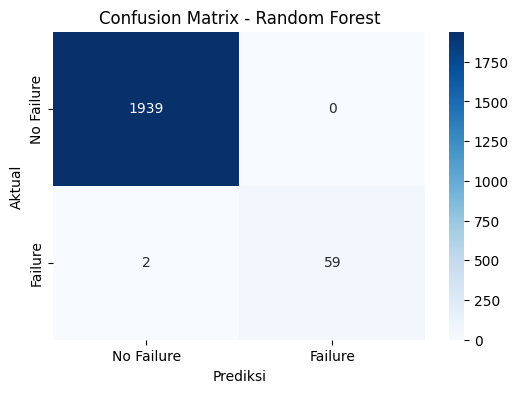

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Inisialisasi dan Training Model
model = RandomForestClassifier(random_state=42, class_weight='balanced')
print("Melatih model Random Forest...")
model.fit(X_train_scaled, y_train)

# 2. Prediksi menggunakan Data Testing
y_pred = model.predict(X_test_scaled)

# 3. Evaluasi - Akurasi & Classification Report
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAkurasi Model: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 4. Evaluasi - Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix (Raw):")
print(cm)

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Failure', 'Failure'],
            yticklabels=['No Failure', 'Failure'])
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.title('Confusion Matrix - Random Forest')
plt.show()

In [ ]:
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# Membuat widget kotak teks untuk parameter utama & mode kegagalan
type_text = widgets.Text(value='L', description='Tipe Mesin:')
air_temp_text = widgets.Text(value='298.1', description='Suhu Udara:')
proc_temp_text = widgets.Text(value='308.6', description='Suhu Proses:')
rot_speed_text = widgets.Text(value='1551', description='Kecepatan:')
torque_text = widgets.Text(value='42.8', description='Torsi:')
tool_wear_text = widgets.Text(value='0', description='Keausan:')

# Widget untuk mode kegagalan (diisi 0 atau 1)
twf_text = widgets.Text(value='0', description='TWF:')
hdf_text = widgets.Text(value='0', description='HDF:')
pwf_text = widgets.Text(value='0', description='PWF:')
osf_text = widgets.Text(value='0', description='OSF:')
rnf_text = widgets.Text(value='0', description='RNF:')

# Tombol dan Output
predict_button = widgets.Button(description="Jalankan Prediksi", button_style='success')
output_box = widgets.Output()

def on_click_predict(b):
    with output_box:
        clear_output()
        try:
            input_data = {
                'Type': type_text.value.strip().upper(),
                'Air temperature [K]': float(air_temp_text.value),
                'Process temperature [K]': float(proc_temp_text.value),
                'Rotational speed [rpm]': int(rot_speed_text.value),
                'Torque [Nm]': float(torque_text.value),
                'Tool wear [min]': int(tool_wear_text.value),
                'TWF': int(twf_text.value),
                'HDF': int(hdf_text.value),
                'PWF': int(pwf_text.value),
                'OSF': int(osf_text.value),
                'RNF': int(rnf_text.value)
            }

            df_input = pd.DataFrame([input_data])
            df_input_encoded = pd.get_dummies(df_input, columns=['Type'], drop_first=True)

            for col in X_train_encoded.columns:
                if col not in df_input_encoded.columns:
                    df_input_encoded[col] = 0
            df_input_encoded = df_input_encoded[X_train_encoded.columns]

            df_input_scaled = df_input_encoded.copy()
            df_input_scaled[numerical_cols] = scaler.transform(df_input_encoded[numerical_cols])

            pred = model.predict(df_input_scaled)[0]
            prob = model.predict_proba(df_input_scaled)[0][1] if hasattr(model, "predict_proba") else 0.0

            print("="*40)
            print("         HASIL PREDIKSI INFERENCE         ")
            print("="*40)
            if pred == 1:
                print(f"⚠️ STATUS: POTENSI KERUSAKAN (FAILURE)")
                print(f"Tingkat Keyakinan: {prob * 100:.2f}%")
            else:
                print(f"✅ STATUS: MESIN AMAN / NORMAL")
                print(f"Tingkat Keyakinan: {(1 - prob) * 100:.2f}%")
            print("="*40)

        except Exception as e:
            print(f"Error: {e}")

predict_button.on_click(on_click_predict)

# Menampilkan semua widget input lengkap
display(
    type_text, air_temp_text, proc_temp_text, rot_speed_text, torque_text, tool_wear_text,
    twf_text, hdf_text, pwf_text, osf_text, rnf_text,
    predict_button, output_box
)

Text(value='L', description='Tipe Mesin:')

Text(value='298.1', description='Suhu Udara:')

Text(value='308.6', description='Suhu Proses:')

Text(value='1551', description='Kecepatan:')

Text(value='42.8', description='Torsi:')

...

Text(value='0', description='PWF:')

Text(value='0', description='OSF:')

Text(value='0', description='RNF:')

Button(button_style='success', description='Jalankan Prediksi', style=ButtonStyle())

Output()